# Project 2: Part B

Alexander Matteson

ee513

In [1]:
# imports:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import rawpy
import cv2
import colour

from scipy.signal import convolve2d
from scipy.ndimage import gaussian_filter, median_filter
from skimage.restoration import denoise_nl_means
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%matplotlib inline

In [2]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

# Main project directory
PROJECT_DIR = r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson"

# Input images
IMG_DIR = os.path.join(PROJECT_DIR, "Img")
DARK_DIR = os.path.join(PROJECT_DIR, "DarkFields")

# Calibration directories
COLOR_DIR = os.path.join(PROJECT_DIR, "ColorCorrection")
SET_USED = "Set2"

# Example scene
SCENE_PATH = os.path.join(IMG_DIR, "TowerPicture.dng")

# Calibration files
DEFECT_MAP_PATH = "defect_map.npz"

In [3]:
# ============================================================
# 2. CLASSICAL PIPELINE PARAMETERS
# ============================================================

# NLM denoising
RED_SIGMA = 0.00505367641233       # Populate from optimized Part A value
GREEN_SIGMA = 0.003512
BLUE_SIGMA = 0.00293508844839

# White balance
WHITE_BALANCE_SET = SET_USED

# Demosaicing
DEMOSAIC_METHODS = ["MHC"]

# Tone mapping
S_CURVE_STRENGTH = 5.0

# Sharpening
SHARPEN_SIGMA = 1.0
SHARPEN_AMOUNT = 0.5

# Future learned-denoiser selection
DENOISER_METHOD = "nlm"

print("Pipeline parameters initialized.")

Pipeline parameters initialized.


In [4]:
from pathlib import Path
import sys

# Add the project directory to Python's import path
project_dir = Path.cwd()
sys.path.insert(0, str(project_dir))

# Import the classical pipeline
import ISP.ClassicPipeline as cp

print("ClassicPipeline imported successfully!")

ClassicPipeline imported successfully!


In [5]:
print(cp.load_dng_mosaic)
print(cp.correct_lens_shading)
print(cp.mhc_demosaic)
print(cp.apply_color_correction)

<function load_dng_mosaic at 0x0000018159F0D1C0>
<function correct_lens_shading at 0x0000018159F0E3E0>
<function mhc_demosaic at 0x0000018159F0F880>
<function apply_color_correction at 0x0000018159F9C360>


### the classical ISP that  we will comapre the learned denoising to:

CFA pattern: RGGB  ->  OK (RGGB)
Input: IMG_0543.DNG
Mosaic shape: (3024, 4032)
Bayer pattern: RGGB
White level: 4095.0
Black levels: [ 528.  528.  528.  528.]
Defect correction applied.
Lens shading correction applied.
LSC mosaic range: 0.0 2167.5419921875
Classical NLM denoising applied.
White balance applied.
MHC demosaicing applied.
Demosaiced RGB shape: (3024, 4032, 3)
Color correction applied.


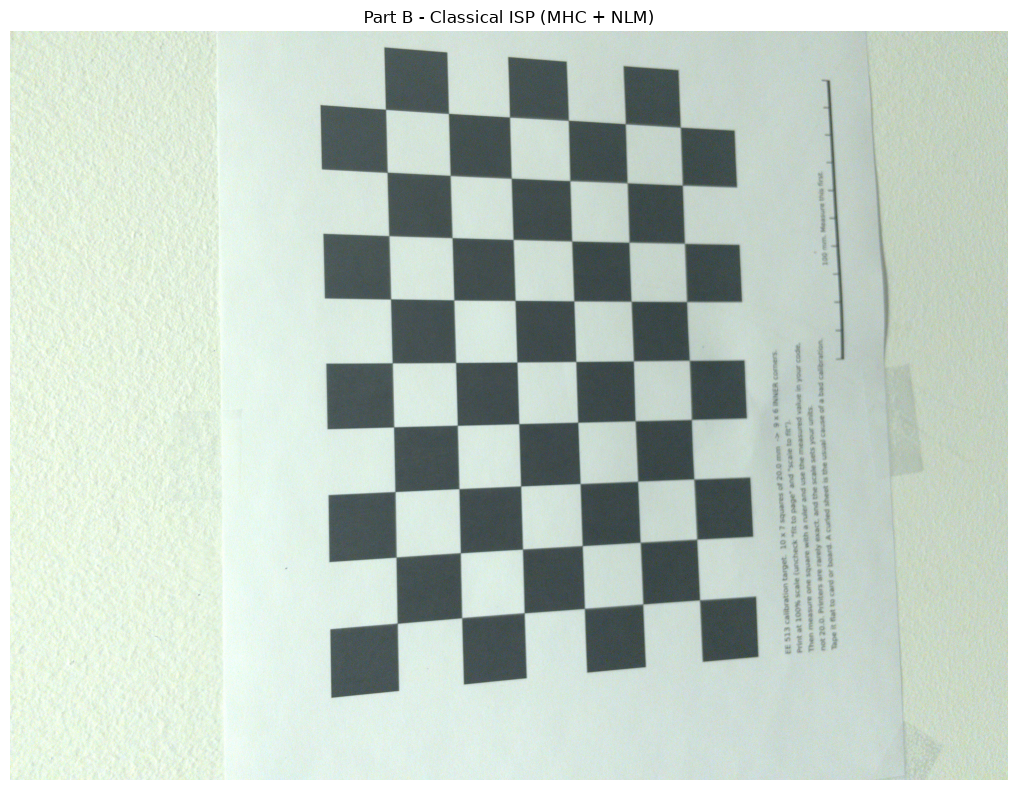

Classical pipeline complete.


In [6]:

# ============================================================
# PART B: CLASSICAL ISP PIPELINE
# Uses functions from ISP.ClassicPipeline
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

# Input image
DNG_PATH = Path(r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\Img\IMG_0543.DNG")

# Calibration files generated in Part A
DEFECT_MAP_PATH = Path(r"defect_map.npz")
LSC_GAIN_PATH = Path(r"lsc_gain.npz")

# Camera white balance gains from Part A: [R, G, B]
WB_GAINS = np.array([
    1.309,  # Replace with Part A red gain
    1.0,  # Green gain
    3.1633  # Blue gain
], dtype=np.float32)

# Camera RGB -> XYZ matrix fitted in Part A
CAMERA_TO_XYZ = np.array([
    [ 1.32354858,  0.69974474,  0.41090646],
    [ 0.05335418,  2.45325158 , 0.0520644 ],
    [ 0.0268082,  -1.49825369,  3.57362769]
], dtype=np.float64)

# IMPORTANT:
# Use the same RGB normalization used when fitting CAMERA_TO_XYZ.
# 4095 is the saturation level you measured in Part A.
RGB_SCALE = 4095.0

# ------------------------------------------------------------
# 2. NLM parameters from Part A
# ------------------------------------------------------------
# Fill in the optimized values you used in Part A.
# Sigma is the noise standard deviation for each CFA plane.
# h, patch_size, and search_window are your optimized NLM settings.

NLM_CONFIG = {
    "R": {
        "sigma": 0.00505367641233,
        "h":  0.0101073528247,
        "patch_size": 11,
        "search_window": 11
    },
    "G": {
        "sigma":  0.003512,
        "h": 0.014048,
        "patch_size": 7,
        "search_window": 7
    },
    "B": {
        "sigma": 0.00293508844839,
        "h":  0.00880526534518,
        "patch_size": 9,
        "search_window": 11
    }
}

# ------------------------------------------------------------
# 3. Optional display processing
# ------------------------------------------------------------

APPLY_S_CURVE = False
S_CURVE_STRENGTH = 6.0

APPLY_UNSHARP_MASK = False
UNSHARP_SIGMA = 1.0
UNSHARP_AMOUNT = 0.5

# ------------------------------------------------------------
# 4. Load DNG and check Bayer pattern
# ------------------------------------------------------------

dng = cp.load_dng_mosaic(str(DNG_PATH))

cp.check_rggb(dng["pattern"])

mosaic_raw = dng["mosaic"]
pattern = np.array(list(dng["pattern"])).reshape(2, 2)

print("Input:", DNG_PATH.name)
print("Mosaic shape:", mosaic_raw.shape)
print("Bayer pattern:", dng["pattern"])
print("White level:", dng["white"])
print("Black levels:", dng["black"])

# ------------------------------------------------------------
# 5. Defect correction
# ------------------------------------------------------------

if DEFECT_MAP_PATH.exists():
    mosaic_defect_corrected = cp.correct_defective_pixels(
        mosaic_raw,
        str(DEFECT_MAP_PATH)
    )
    print("Defect correction applied.")
else:
    mosaic_defect_corrected = mosaic_raw.copy()
    print("WARNING: No defect map found; skipping defect correction.")

# ------------------------------------------------------------
# 6. Lens shading correction
# ------------------------------------------------------------

if not LSC_GAIN_PATH.exists():
    raise FileNotFoundError(
        f"Lens shading calibration not found: {LSC_GAIN_PATH}"
    )

mosaic_lsc = cp.correct_lens_shading(
    mosaic_defect_corrected,
    gain_npz=str(LSC_GAIN_PATH),
    keep_black_level=False
)

print("Lens shading correction applied.")
print("LSC mosaic range:",
      float(mosaic_lsc.min()),
      float(mosaic_lsc.max()))

# ------------------------------------------------------------
# 7. Classical NLM denoising
# ------------------------------------------------------------

def denoise_classical_bayer(mosaic, pattern, config):
    """
    Apply NLM independently to the R, G1, G2, and B CFA planes.
    Both green planes use the same optimized green parameters.
    """

    mosaic = np.asarray(mosaic, dtype=np.float32)
    denoised = np.empty_like(mosaic)

    for dy in range(2):
        for dx in range(2):

            color = pattern[dy, dx]
            params = config[color]

            if any(value is None for value in params.values()):
                raise ValueError(
                    f"Please fill in all NLM parameters for color {color}."
                )

            plane = mosaic[dy::2, dx::2]

            denoised_plane = cp.nlm_denoise(
                plane,
                sigma=params["sigma"],
                h=params["h"],
                patch_size=params["patch_size"],
                search_window=params["search_window"]
            )

            denoised[dy::2, dx::2] = denoised_plane

    return denoised


mosaic_denoised = denoise_classical_bayer(
    mosaic_lsc,
    pattern,
    NLM_CONFIG
)

print("Classical NLM denoising applied.")

# ------------------------------------------------------------
# 8. White balance
# ------------------------------------------------------------

mosaic_wb = cp.apply_white_balance_mosaic(
    mosaic_denoised,
    WB_GAINS
)

print("White balance applied.")

# ------------------------------------------------------------
# 9. MHC demosaicing
# ------------------------------------------------------------
CH = {"R": 0, "G": 1, "B": 2}
rgb_mhc = cp.mhc_demosaic(
    mosaic_wb,
    pattern,
    with_correction=True
)

print("MHC demosaicing applied.")
print("Demosaiced RGB shape:", rgb_mhc.shape)

# ------------------------------------------------------------
# 10. Normalize camera RGB
# ------------------------------------------------------------
# Must match the normalization used when fitting CAMERA_TO_XYZ.

rgb_camera = rgb_mhc / RGB_SCALE

# ------------------------------------------------------------
# 11. Color correction: camera RGB -> XYZ -> sRGB
# ------------------------------------------------------------

_, _, source_illuminant = cp.load_reference()

rgb_srgb, xyz_corrected = cp.apply_color_correction(
    rgb_camera,
    CAMERA_TO_XYZ,
    source_illuminant,
    exposure_scale=1.0
)

# apply_color_correction already returns gamma-encoded sRGB.
# Do not apply another standard sRGB gamma conversion here.

rgb_classical = np.clip(rgb_srgb, 0.0, 1.0)

print("Color correction applied.")

# ------------------------------------------------------------
# 12. Optional S-curve
# ------------------------------------------------------------

if APPLY_S_CURVE:
    rgb_classical = cp.apply_s_curve(
        rgb_classical,
        strength=S_CURVE_STRENGTH
    )

# ------------------------------------------------------------
# 13. Optional unsharp masking
# ------------------------------------------------------------

if APPLY_UNSHARP_MASK:
    rgb_classical = cp.unsharp_mask(
        rgb_classical,
        sigma=UNSHARP_SIGMA,
        amount=UNSHARP_AMOUNT
    )

# ------------------------------------------------------------
# 14. Display final classical output
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))
plt.imshow(np.clip(rgb_classical, 0, 1))
plt.title("Part B - Classical ISP (MHC + NLM)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Classical pipeline complete.")


### Create training pairs:

1. register 16 burst images
2. average the 16 burst images
3. add poisson gaussian noise to the clean averaged image
4. create patches of the clean image and noisy pairs
5. augment data
6. create training-validation-test split

In [8]:
# register images:
# ------------------------------------------------------------
# 1. Imports and configuration
# ------------------------------------------------------------

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

from scipy.ndimage import shift as ndi_shift
from skimage.registration import phase_cross_correlation

import ISP.ClassicPipeline as cp


base_dir = Path(
    r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\AvgImages"
)

output_dir = base_dir / "RegisteredAverages"
output_dir.mkdir(exist_ok=True)

# Burst 1 is reserved as the held-out test burst
burst_numbers = [1, 2, 3, 4]

upsample_factor = 10


def natural_sort_key(path):
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r"(\d+)", path.name)
    ]


# ------------------------------------------------------------
# 2. CFA-plane alignment helper
# ------------------------------------------------------------

def align_bayer_mosaic(mosaic, shift):
    """
    Apply the same translation independently to the four RGGB
    CFA planes, preserving the Bayer pattern.

    shift is expressed in half-resolution CFA-plane pixels.
    """

    aligned = np.empty(mosaic.shape, dtype=np.float32)

    # Extract four CFA planes
    r  = mosaic[0::2, 0::2]
    g1 = mosaic[0::2, 1::2]
    g2 = mosaic[1::2, 0::2]
    b  = mosaic[1::2, 1::2]

    # Apply identical translation to each plane
    r_aligned = ndi_shift(
        r, shift=shift, order=1, mode="reflect", prefilter=False
    )

    g1_aligned = ndi_shift(
        g1, shift=shift, order=1, mode="reflect", prefilter=False
    )

    g2_aligned = ndi_shift(
        g2, shift=shift, order=1, mode="reflect", prefilter=False
    )

    b_aligned = ndi_shift(
        b, shift=shift, order=1, mode="reflect", prefilter=False
    )

    # Reassemble RGGB mosaic
    aligned[0::2, 0::2] = r_aligned
    aligned[0::2, 1::2] = g1_aligned
    aligned[1::2, 0::2] = g2_aligned
    aligned[1::2, 1::2] = b_aligned

    return aligned


# ------------------------------------------------------------
# 3. Process each burst independently
# ------------------------------------------------------------

burst_averages = {}

for burst_num in burst_numbers:

    print(f"\n{'='*50}")
    print(f"Processing Burst {burst_num}")
    print(f"{'='*50}")

    burst_dir = base_dir / str(burst_num)

    image_paths = sorted(
        burst_dir.glob("*.dng"),
        key=natural_sort_key
    )

    if len(image_paths) == 0:
        print(f"No DNG files found in {burst_dir}")
        continue

    print(f"Found {len(image_paths)} DNG images.")

    # --------------------------------------------------------
    # Load DNG raw mosaics
    # --------------------------------------------------------

    mosaics = []
    reference_black = None

    for path in image_paths:

        d = cp.load_dng_mosaic(str(path))

        if d["pattern"] != "RGGB":
            raise ValueError(
                f"{path.name}: expected RGGB, got {d['pattern']}"
            )

        mosaic = d["mosaic"].astype(np.float32)

        if reference_black is None:
            reference_black = d["black"].copy()
        elif not np.allclose(d["black"], reference_black):
            raise ValueError(
                f"Black levels differ within Burst {burst_num}"
            )

        mosaics.append(mosaic)

    reference = mosaics[0]

    if any(m.shape != reference.shape for m in mosaics):
        raise ValueError(
            f"Image dimensions differ within Burst {burst_num}"
        )

    # --------------------------------------------------------
    # Registration reference: first green CFA plane
    # --------------------------------------------------------

    reference_green = reference[0::2, 1::2]

    aligned_mosaics = []
    shifts = []

    for i, moving in enumerate(mosaics):

        if i == 0:

            shift = np.array([0.0, 0.0])
            aligned = moving.copy()

        else:

            moving_green = moving[0::2, 1::2]

            # Estimate subpixel translation
            shift, error, phase_diff = phase_cross_correlation(
                reference_green,
                moving_green,
                upsample_factor=upsample_factor
            )

            # Apply shift to all four CFA planes
            aligned = align_bayer_mosaic(moving, shift)

        aligned_mosaics.append(aligned)
        shifts.append(shift)

        print(
            f"{image_paths[i].name}: "
            f"dy = {shift[0]:7.3f}, "
            f"dx = {shift[1]:7.3f} "
            f"(CFA-plane pixels)"
        )

    # --------------------------------------------------------
    # Average aligned mosaics
    # --------------------------------------------------------

    aligned_stack = np.stack(aligned_mosaics, axis=0)

    average_mosaic = np.mean(
        aligned_stack,
        axis=0
    ).astype(np.float32)

    burst_averages[burst_num] = average_mosaic

    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    burst_output = output_dir / f"Burst_{burst_num}"
    burst_output.mkdir(exist_ok=True)

    # Average raw mosaic
    tifffile.imwrite(
        burst_output / "average_raw_mosaic.tif",
        average_mosaic
    )

    # Save shifts
    shift_df = pd.DataFrame({
        "filename": [p.name for p in image_paths],
        "shift_y_CFA_pixels": [s[0] for s in shifts],
        "shift_x_CFA_pixels": [s[1] for s in shifts],
        "shift_y_raw_pixels": [2*s[0] for s in shifts],
        "shift_x_raw_pixels": [2*s[1] for s in shifts]
    })

    shift_df.to_csv(
        burst_output / "registration_shifts.csv",
        index=False
    )

    # Save individual aligned frames
    aligned_dir = burst_output / "AlignedFrames"
    aligned_dir.mkdir(exist_ok=True)

    for path, aligned in zip(image_paths, aligned_mosaics):

        tifffile.imwrite(
            aligned_dir / f"{path.stem}_aligned.tif",
            aligned.astype(np.float32)
        )

    print(f"Average saved: {burst_output / 'average_raw_mosaic.tif'}")


print("\nFinished processing all bursts.")


Processing Burst 1
Found 16 DNG images.
RawCam-2026-11-24-160835.dng: dy =   0.000, dx =   0.000 (CFA-plane pixels)
RawCam-2026-11-24-160836.dng: dy =  -0.500, dx =  -2.300 (CFA-plane pixels)
RawCam-2026-11-24-160838.dng: dy =  -0.500, dx =  -3.100 (CFA-plane pixels)
RawCam-2026-11-24-160839.dng: dy =  -0.200, dx =  -2.800 (CFA-plane pixels)
RawCam-2026-11-24-160840.dng: dy =   0.600, dx =  -3.400 (CFA-plane pixels)
RawCam-2026-11-24-160841.dng: dy =   0.700, dx =  -2.000 (CFA-plane pixels)
RawCam-2026-11-24-160842.dng: dy =   0.900, dx =  -2.400 (CFA-plane pixels)
RawCam-2026-11-24-160843.dng: dy =   1.000, dx =  -3.000 (CFA-plane pixels)
RawCam-2026-11-24-160845.dng: dy =   1.100, dx =  -3.100 (CFA-plane pixels)
RawCam-2026-11-24-160846.dng: dy =   0.200, dx =  -4.200 (CFA-plane pixels)
RawCam-2026-11-24-160847.dng: dy =   0.200, dx =  -2.200 (CFA-plane pixels)
RawCam-2026-11-24-160848.dng: dy =   0.300, dx =  -2.700 (CFA-plane pixels)
RawCam-2026-11-24-160849.dng: dy =   0.300, dx 

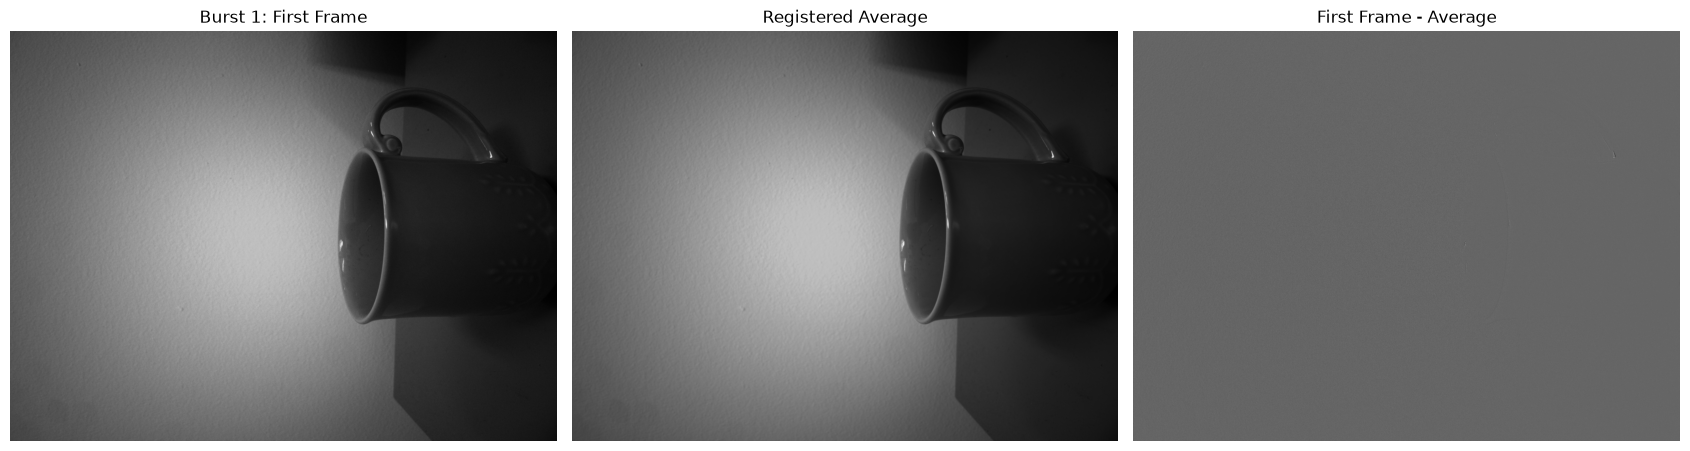

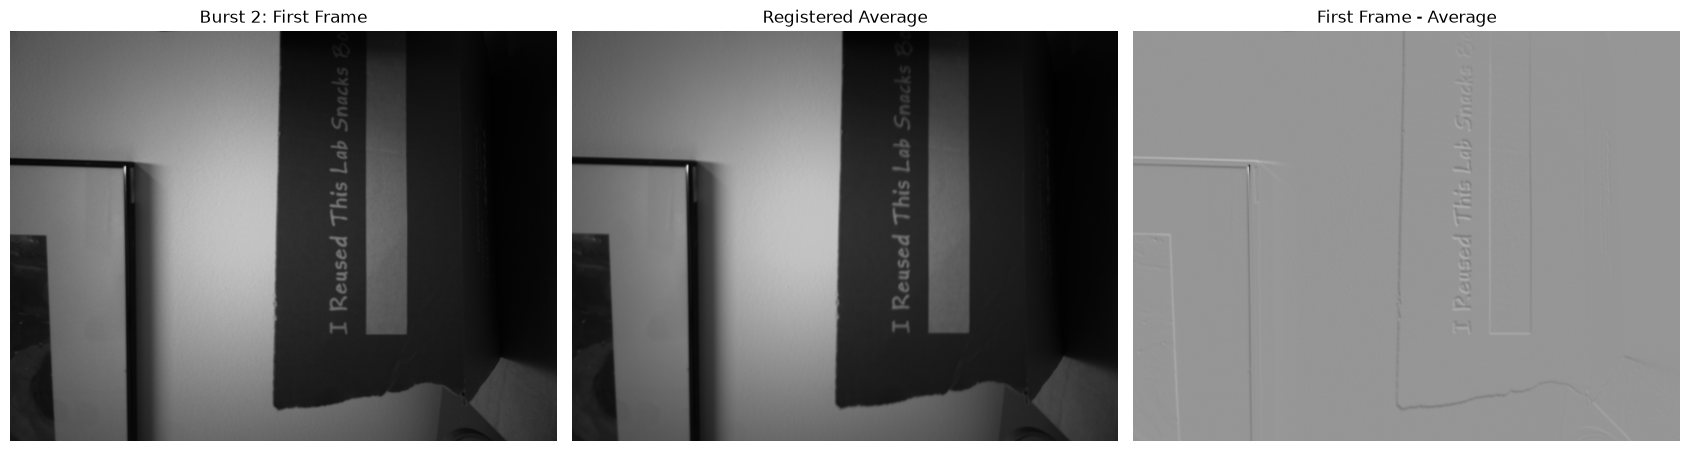

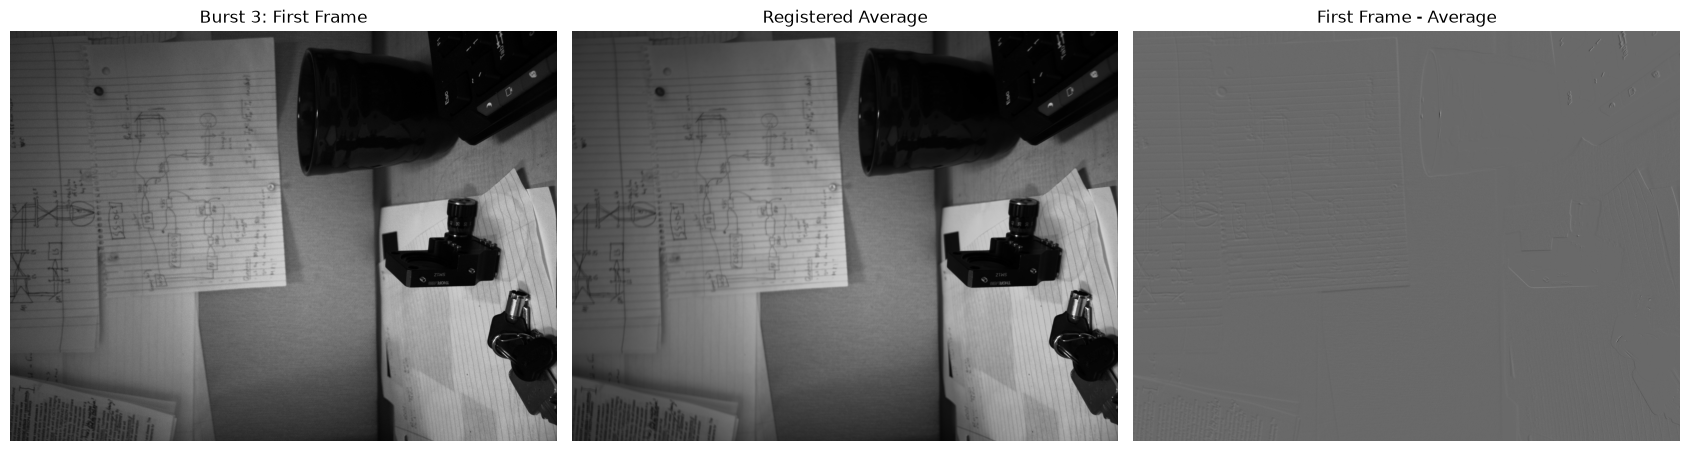

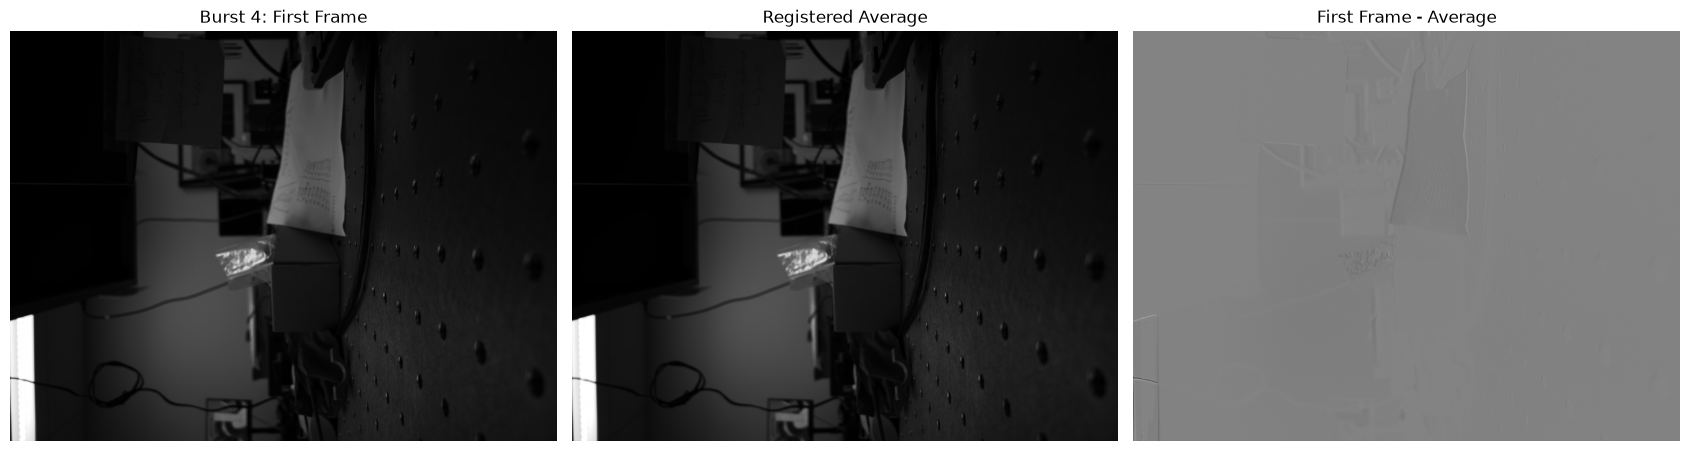

In [9]:
# ------------------------------------------------------------
# 4. Display first frame vs. registered average
# ------------------------------------------------------------

for burst_num, average in burst_averages.items():

    burst_dir = base_dir / str(burst_num)

    image_paths = sorted(
        burst_dir.glob("*.dng"),
        key=natural_sort_key
    )

    first_dng = cp.load_dng_mosaic(str(image_paths[0]))
    first_mosaic = first_dng["mosaic"].astype(np.float32)

    fig, ax = plt.subplots(1, 3, figsize=(17, 5))

    vmin = np.percentile(first_mosaic, 1)
    vmax = np.percentile(first_mosaic, 99)

    ax[0].imshow(first_mosaic, cmap="gray", vmin=vmin, vmax=vmax)
    ax[0].set_title(f"Burst {burst_num}: First Frame")

    ax[1].imshow(average, cmap="gray", vmin=vmin, vmax=vmax)
    ax[1].set_title("Registered Average")

    ax[2].imshow(first_mosaic - average, cmap="gray")
    ax[2].set_title("First Frame - Average")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# add poisson-gaussian noise to the clean images:
ReadNoise = 2.95
Gain =  0.4099



In [7]:
def add_poisson_gaussian_noise(clean, a, b):
    """
    Add signal-dependent Poisson-Gaussian noise.
    a and b must match the intensity units of clean.
    """
    clean = np.clip(clean, 0, None)

    noise_std = np.sqrt(a * clean + b)
    noisy = clean + np.random.normal(0, noise_std, clean.shape)

    return noisy.astype(np.float32)